# Machine Learning: Bioinformatics and Sequence ML

> **Who is this for:** you know Python, basic probability and a little ML, and you are curious how the same ideas (dynamic programming, hashing, HMMs, CNNs, language models) are used on DNA and proteins. Also for BS/MS students taking a bioinformatics or computational biology elective, and for interviews at biotech/health-AI companies.
>
> **What you will learn:**
> - DNA and protein **alphabets**, reverse complements, GC content and translation with the genetic code; generating synthetic sequences with **planted motifs**
> - **Global (Needleman–Wunsch) and local (Smith–Waterman) alignment** from scratch, with traceback plots, scoring matrices (BLOSUM62) and brute-force checks
> - **k-mer counting** with hashing and a Count-Min sketch, and **MinHash** (Mash) distances that rebuild a family tree of genomes
> - **Suffix arrays** and the **BWT/FM-index** for fast motif search and read mapping (with the pigeonhole seed trick)
> - **HMMs:** CpG-island decoding with **Viterbi** and forward–backward, and profiles (PWMs) as the core of profile HMMs
> - **Sequence classification:** k-mer bag-of-words + logistic regression vs a **1-D CNN** in PyTorch, and reading the motif the CNN learned
> - **Embedding and clustering** protein families; what **protein language models** are
> - **Data ethics for genomic data**, including a membership-inference demo on synthetic genotypes
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [dynamic programming](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb) (edit distance); [logistic regression](../01_supervised/02_logistic_regression.ipynb); [PyTorch from zero](../../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb) and [CNNs](../../05_Deep_Learning/03_cnn.ipynb). Helpful: [HMMs in classical AI](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) (section 11), [streaming and sketching](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb) and [suffix arrays](../../00_AI_Fundamentals/advanced_algorithms/08_advanced_data_structures.ipynb). No biology background is needed: every term is explained.
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. All sequences are synthetic (no real genomes or people). The whole notebook runs in about a minute or two.
>
> **Optional track:** this notebook is part of the university-level fundamentals track (domain electives); recommended for BS/MS AI students and interview prep. It follows Durbin, Eddy, Krogh & Mitchison, *Biological Sequence Analysis* (1998) and Jones & Pevzner, *An Introduction to Bioinformatics Algorithms* (2004).

## Explained simply

Every living thing carries an instruction book written with only four letters: **A, C, G and T** (that is DNA). Parts of the book are copied and translated into proteins, which are written with 20 letters (the amino acids). So biology is full of very long **texts**, and many tools we use for text also work here.

The most common question is "how similar are these two texts?" A spell-checker does this when it suggests "receive" for "recieve"; a teacher does it when comparing two essays for copying. In biology, similar genes in a human and a mouse usually do similar jobs, so finding similarity tells you what an unknown gene might do. To compare, we **line up** the two texts, allowing a few letters to be skipped (gaps), and give points for matches.

**Tiny example.** Compare `ACGT` with `AGT`. Put a gap under the C:

```
A C G T
A - G T
```
That is 3 matches (+1 each) and 1 gap (−1), a score of 3 − 1 = **2**. Any other way of lining them up scores less, so this is the best alignment.

We will also hunt for short "words" (**motifs**) that switch genes on, spot regions with an unusual letter mix using a model that guesses hidden states (an HMM), and train small neural networks that learn these words by themselves.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Sequence alignment | line up two texts with gaps to see how alike they are | BLAST searches, spell-checkers, `diff` for code |
| k-mer | a short word of length k cut from a long text | genome comparison, plagiarism detection, LLM data dedup |
| Hidden Markov model | guess hidden "modes" from what you can see | gene finding, speech recognition, part-of-speech tagging |

## Table of contents
0. Setup
1. Biological sequences as strings
2. Pairwise alignment: Needleman–Wunsch and Smith–Waterman
3. k-mers, Count-Min and MinHash genome distances
4. Suffix arrays, the BWT and read mapping
5. Hidden Markov models: CpG islands and profiles
6. Sequence classification: k-mers + logistic regression vs a 1-D CNN
7. Embedding and clustering sequences; protein language models
8. Data ethics for genomic data
9. Summary table
10. 🔗 How this connects to modern AI
11. Recap, practice problems, further reading

---
## 0. Setup

> 💬 **In plain English:** load the tools, fix the random seeds, and keep CPU use modest.

In [1]:
# Standard setup used throughout this notebook
import random, math, time, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)          # reproducible random numbers (Python)
np.random.seed(42)       # reproducible random numbers (NumPy)
rng = np.random.default_rng(42)   # the generator we pass around explicitly

# One consistent, colour-blind-friendly palette for every chart in this module
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

import itertools, hashlib
from collections import Counter
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, adjusted_rand_score, roc_curve
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits
threadpool_limits(1)              # small data: one thread is fast and keeps shared machines responsive

import torch
import torch.nn as nn
torch.set_num_threads(2)
torch.manual_seed(42)
print("torch", torch.__version__)

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


torch 2.12.1+cpu


---
## 1. Biological sequences as strings

> 💬 **In plain English:** DNA is a string over 4 letters, protein a string over 20. The two strands of DNA are mirror copies, and every 3 DNA letters code for one protein letter.

**Definitions.**
- **DNA** is a string over $\Sigma_{DNA} = \{A, C, G, T\}$ (RNA uses U instead of T). The two strands pair A–T and C–G and run in opposite directions, so the other strand of `ATGC` read in its own direction is the **reverse complement** `GCAT`.
- **GC content** = fraction of G and C letters. It varies between species and regions, and it is a classic simple feature.
- A **codon** is a triplet of DNA letters; the **genetic code** maps the 64 codons to 20 amino acids plus 3 **stop** codons (`TAA`, `TAG`, `TGA`). `ATG` codes for methionine (M) and usually marks the **start** of a gene. Several codons can code for the same amino acid (the code is **degenerate**).
- A **protein** is a string over 20 amino-acid letters, e.g. `MKT...`.
- A **motif** is a short, recurring pattern with a biological function, such as a transcription-factor binding site. Real motifs are fuzzy, so we describe them by a **position weight matrix (PWM)**: for each position, the probability of each letter.
- **Information content** of a PWM column, in bits: $IC = 2 - H = 2 + \sum_b p_b \log_2 p_b$ (2 bits is the maximum for 4 letters). Sequence "logos" stack letters to this height.

**Worked example.** `ATGGCC TAA`: codons `ATG` → M, `GCC` → A, `TAA` → stop, so the protein is `MA`. GC content of `ATGGCCTAA` = 4/9 ≈ 0.44.

In [2]:
DNA = "ACGT"
COMP = str.maketrans("ACGT", "TGCA")

def revcomp(s):
    """Reverse complement of a DNA string."""
    return s.translate(COMP)[::-1]

def gc_content(s):
    return (s.count("G") + s.count("C")) / len(s)

# The standard genetic code (NCBI translation table 1), built from its compact form
BASES = "TCAG"
AA_BY_CODON = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODON_TABLE = {a + b + c: AA_BY_CODON[16 * i + 4 * j + k]
               for i, a in enumerate(BASES) for j, b in enumerate(BASES) for k, c in enumerate(BASES)}
assert CODON_TABLE["ATG"] == "M" and CODON_TABLE["TGG"] == "W"
assert {c for c, a in CODON_TABLE.items() if a == "*"} == {"TAA", "TAG", "TGA"}
assert len(set(CODON_TABLE.values()) - {"*"}) == 20

def translate(s):
    """Translate DNA to protein, stopping at the first stop codon."""
    prot = []
    for i in range(0, len(s) - 2, 3):
        aa = CODON_TABLE[s[i:i + 3]]
        if aa == "*":
            break
        prot.append(aa)
    return "".join(prot)

s = "ATGGCCTAA"
print("sequence:", s, "| reverse complement:", revcomp(s), "| GC:", round(gc_content(s), 3),
      "| protein:", translate(s))
assert revcomp(revcomp(s)) == s and translate(s) == "MA"
print("codons per amino acid:", dict(sorted(Counter(v for v in CODON_TABLE.values()).items(), key=lambda kv: -kv[1])[:6]), "...")

sequence: ATGGCCTAA | reverse complement: TTAGGCCAT | GC: 0.444 | protein: MA
codons per amino acid: {'L': 6, 'S': 6, 'R': 6, 'P': 4, 'T': 4, 'V': 4} ...


five sampled motif instances: ['TGGCGTCAAGCT', 'TGACGACATGTT', 'TGACGTCTCGCA', 'TGACGTCATGCA', 'TGAAGTCAGGCA']
information content (bits): [1.37 1.37 0.4  1.63 1.63 0.21 1.37 1.37 0.08 0.96 1.37 0.4 ] | total 12.17


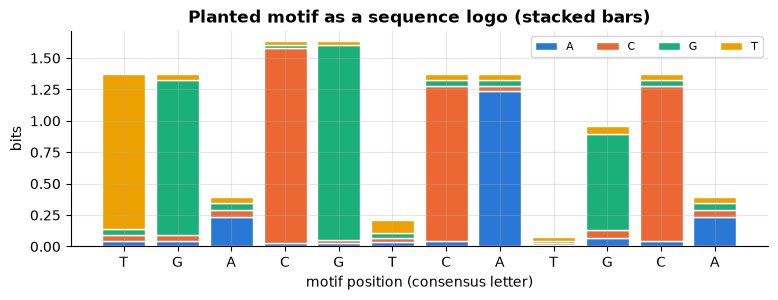

In [3]:
def random_dna(n, gc=0.5, rng=rng):
    """i.i.d. background DNA with a given GC content."""
    p = [(1 - gc) / 2, gc / 2, gc / 2, (1 - gc) / 2]           # A, C, G, T
    return "".join(rng.choice(list(DNA), size=n, p=p))

# A 12-bp motif described by a PWM: some positions are strict, some are fuzzy
CONSENSUS = "TGACGTCATGCA"
STRENGTH = np.array([0.9, 0.9, 0.6, 0.95, 0.95, 0.5, 0.9, 0.9, 0.4, 0.8, 0.9, 0.6])
PWM = np.full((len(CONSENSUS), 4), 0.0)
for i, (b, st) in enumerate(zip(CONSENSUS, STRENGTH)):
    PWM[i] = (1 - st) / 3                       # the other three letters share the rest
    PWM[i, DNA.index(b)] = st
assert np.allclose(PWM.sum(1), 1)

def sample_motif(rng=rng):
    return "".join(DNA[rng.choice(4, p=row)] for row in PWM)

def plant(seq, motif, pos):
    return seq[:pos] + motif + seq[pos + len(motif):]

ic = 2 + (PWM * np.log2(PWM)).sum(1)            # information content per position (bits)
print("five sampled motif instances:", [sample_motif() for _ in range(5)])
print("information content (bits):", np.round(ic, 2), "| total", round(ic.sum(), 2))

fig, ax = plt.subplots(figsize=(9, 2.8))
bottom = np.zeros(len(CONSENSUS))
for j, b in enumerate(DNA):                     # a simple "logo": letter heights = p * IC
    h = PWM[:, j] * ic
    ax.bar(range(len(CONSENSUS)), h, bottom=bottom, color=PALETTE[j], edgecolor="white", label=b)
    bottom += h
ax.set_xticks(range(len(CONSENSUS)), list(CONSENSUS))
ax.set(title="Planted motif as a sequence logo (stacked bars)", xlabel="motif position (consensus letter)",
       ylabel="bits"); ax.legend(ncol=4, fontsize=8)
plt.show()

**What just happened?** We built the genetic code from its standard compact form and checked it (3 stop codons, 20 amino acids, `ATG` = M). Then we defined a 12-letter motif by a PWM: strict positions (95% one letter) carry about 1.6 bits, fuzzy positions (40%) only about 0.1 bits. The sampled instances differ from the consensus at a few positions each, just like real binding sites. The stacked-bar "logo" shows the strict positions as tall columns.

**Complexity:** reverse complement, GC content and translation are all $O(n)$.

> ⚠️ **Common mistake:** forgetting the other strand. A motif or gene can sit on either strand, so searches usually scan both `s` and `revcomp(s)`, and k-mer tools often count **canonical** k-mers (the smaller of a k-mer and its reverse complement).

---
## 2. Pairwise alignment: Needleman–Wunsch and Smith–Waterman

> 💬 **In plain English:** slide two strings against each other, allowing gaps, so that as many letters as possible line up. Global alignment lines up the whole of both strings; local alignment finds the best matching pieces.

**Definitions.**
- An **alignment** of $x$ (length $n$) and $y$ (length $m$) inserts gap symbols `-` so both have the same length, then pairs the columns. Each column is a **match/mismatch** (scored by $s(a, b)$) or a **gap** (penalty $g < 0$; this is a **linear** gap cost).
- **Global alignment (Needleman–Wunsch, 1970)** maximises the total score over full-length alignments. Recurrence, with $F(i, 0) = ig$, $F(0, j) = jg$:

$$F(i,j) = \max\{F(i-1,j-1) + s(x_i, y_j),\; F(i-1,j) + g,\; F(i,j-1) + g\}.$$

- **Local alignment (Smith–Waterman, 1981)** finds the best-scoring pair of **substrings**: add 0 to the max (start fresh anywhere), initialise the borders to 0, and trace back from the **largest cell** until a 0.
- **Scoring matrices** for proteins, e.g. **BLOSUM62** (Henikoff & Henikoff, 1992), are log-odds scores of how often two amino acids replace each other in conserved blocks of related proteins (62 = blocks clustered at 62% identity). Positive = substitution more common than chance.
- **Affine gaps** ($g_{\text{open}} + (L-1)\,g_{\text{extend}}$) model one long insertion as more likely than many short ones; Gotoh's algorithm handles them with three DP matrices in the same $O(nm)$ time.

This is the edit-distance DP from [dsa/09](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb) with scores instead of costs.

**Worked example by hand:** `ACG` vs `AG`, match +1, mismatch −1, gap −1. Rows are `ACG`, columns `AG`:

|   | – | A | G |
|---|---|---|---|
| – | 0 | −1 | −2 |
| A | −1 | **1** | 0 |
| C | −2 | **0** | 0 |
| G | −3 | −1 | **1** |

Traceback from the bottom-right (1): diagonal G/G (+1) ← up C/– (−1) ← diagonal A/A (+1): `ACG` / `A-G`, score 1.

In [4]:
def nw_align(x, y, score, gap):
    """Needleman-Wunsch global alignment (linear gaps). score(a, b) -> number. Returns (score, ax, ay, F)."""
    n, m = len(x), len(y)
    F = np.zeros((n + 1, m + 1))
    F[:, 0] = gap * np.arange(n + 1)                    # x aligned against nothing: all gaps
    F[0, :] = gap * np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            F[i, j] = max(F[i - 1, j - 1] + score(x[i - 1], y[j - 1]),   # match / mismatch
                          F[i - 1, j] + gap,                             # gap in y
                          F[i, j - 1] + gap)                             # gap in x
    ax, ay, i, j = [], [], n, m                          # traceback from the corner
    while i > 0 or j > 0:
        if i > 0 and j > 0 and np.isclose(F[i, j], F[i - 1, j - 1] + score(x[i - 1], y[j - 1])):
            ax.append(x[i - 1]); ay.append(y[j - 1]); i -= 1; j -= 1
        elif i > 0 and np.isclose(F[i, j], F[i - 1, j] + gap):
            ax.append(x[i - 1]); ay.append("-"); i -= 1
        else:
            ax.append("-"); ay.append(y[j - 1]); j -= 1
    return F[n, m], "".join(reversed(ax)), "".join(reversed(ay)), F

def sw_align(x, y, score, gap):
    """Smith-Waterman local alignment (linear gaps). Returns (score, ax, ay, H, path)."""
    n, m = len(x), len(y)
    H = np.zeros((n + 1, m + 1))
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            H[i, j] = max(0.0, H[i - 1, j - 1] + score(x[i - 1], y[j - 1]),
                          H[i - 1, j] + gap, H[i, j - 1] + gap)
    i, j = np.unravel_index(np.argmax(H), H.shape)      # start at the best cell
    best, ax, ay, path = H[i, j], [], [], [(i, j)]
    while H[i, j] > 0:
        if np.isclose(H[i, j], H[i - 1, j - 1] + score(x[i - 1], y[j - 1])):
            ax.append(x[i - 1]); ay.append(y[j - 1]); i -= 1; j -= 1
        elif np.isclose(H[i, j], H[i - 1, j] + gap):
            ax.append(x[i - 1]); ay.append("-"); i -= 1
        else:
            ax.append("-"); ay.append(y[j - 1]); j -= 1
        path.append((i, j))
    return best, "".join(reversed(ax)), "".join(reversed(ay)), H, path[::-1]

def simple_score(match, mismatch):
    return lambda a, b: match if a == b else mismatch

def column_score(ax, ay, score, gap):
    """Score an alignment column by column (used to double-check tracebacks)."""
    return sum(gap if "-" in (a, b) else score(a, b) for a, b in zip(ax, ay))

# Hand example and two textbook examples (the Wikipedia articles use these parameters)
sc, ax_, ay_, _ = nw_align("ACG", "AG", simple_score(1, -1), -1)
print(f"ACG vs AG   : score {sc:.0f}\n  {ax_}\n  {ay_}")
sc, ax_, ay_, F = nw_align("GATTACA", "GCATGCU", simple_score(1, -1), -1)
print(f"NW GATTACA vs GCATGCU: score {sc:.0f}\n  {ax_}\n  {ay_}")
assert sc == 0 and column_score(ax_, ay_, simple_score(1, -1), -1) == 0
sc, ax_, ay_, H, path = sw_align("TGTTACGG", "GGTTGACTA", simple_score(3, -3), -2)
print(f"SW TGTTACGG vs GGTTGACTA: score {sc:.0f}\n  {ax_}\n  {ay_}")
assert sc == 13 and (ax_, ay_) == ("GTT-AC", "GTTGAC")

ACG vs AG   : score 1
  ACG
  A-G
NW GATTACA vs GCATGCU: score 0
  G-ATTACA
  GCA-TGCU
SW TGTTACGG vs GGTTGACTA: score 13
  GTT-AC
  GTTGAC


In [5]:
# Brute force: enumerate EVERY alignment of two short strings and keep the best score
def all_alignments(x, y):
    if not x and not y:
        yield "", ""
        return
    if x and y:
        for a, b in all_alignments(x[1:], y[1:]):
            yield x[0] + a, y[0] + b
    if x:
        for a, b in all_alignments(x[1:], y):
            yield x[0] + a, "-" + b
    if y:
        for a, b in all_alignments(x, y[1:]):
            yield "-" + a, y[0] + b

def brute_global(x, y, score, gap):
    return max(column_score(a, b, score, gap) for a, b in all_alignments(x, y))

def brute_local(x, y, score, gap):
    best = 0
    for i in range(len(x)):
        for i2 in range(i + 1, len(x) + 1):
            for j in range(len(y)):
                for j2 in range(j + 1, len(y) + 1):
                    best = max(best, brute_global(x[i:i2], y[j:j2], score, gap))
    return best

n_align = sum(1 for _ in all_alignments("ACGTAC", "AGTCA"))
r = np.random.default_rng(7)
for trial in range(60):
    x = "".join(r.choice(list(DNA), r.integers(1, 6))); y = "".join(r.choice(list(DNA), r.integers(1, 6)))
    f = simple_score(int(r.integers(1, 4)), -int(r.integers(1, 4))); g = -int(r.integers(1, 4))
    nw = nw_align(x, y, f, g); sw = sw_align(x, y, f, g)
    assert np.isclose(nw[0], brute_global(x, y, f, g)) and np.isclose(nw[0], column_score(nw[1], nw[2], f, g))
    if trial < 25:
        assert np.isclose(sw[0], brute_local(x, y, f, g))
print(f"NW and SW agree with exhaustive search on random short pairs "
      f"(e.g. ACGTAC vs AGTCA already has {n_align:,} possible alignments)")

NW and SW agree with exhaustive search on random short pairs (e.g. ACGTAC vs AGTCA already has 3,653 possible alignments)


**What just happened?** Both algorithms reproduce the textbook results: the global alignment of `GATTACA`/`GCATGCU` scores 0, and the best local alignment of `TGTTACGG`/`GGTTGACTA` is `GTT-AC`/`GTTGAC` with score 13. Then we checked them against **exhaustive search**: even two strings of length 6 and 5 have 3,653 possible alignments (the number grows exponentially), yet DP finds the best one by filling a small table.

**Complexity:** $O(nm)$ time and space for the score and traceback. The score alone needs $O(\min(n, m))$ space (keep two rows); Hirschberg's divide-and-conquer recovers the alignment in linear space. Aligning a 1,000-letter query against a 3-billion-letter genome this way is far too slow, which is why **BLAST** uses heuristics: find short exact **seeds** (k-mers), then extend them (section 4 uses the same idea).

Now visualise the DP table and the traceback path, and align two proteins with BLOSUM62.

    W  Y  F  C  L  I
W  11  2  1 -2 -2 -3
Y   2  7  3 -2 -1 -1
F   1  3  6 -2  0  0
C  -2 -2 -2  9 -1 -1
L  -2 -1  0 -1  4  2
I  -3 -1  0 -1  2  4

global (BLOSUM62, gap -8): score -8
  HEAGAWGHEE
  --P-AWHEAE
local  (BLOSUM62, gap -8): score 20
  AWGHE
  AW-HE


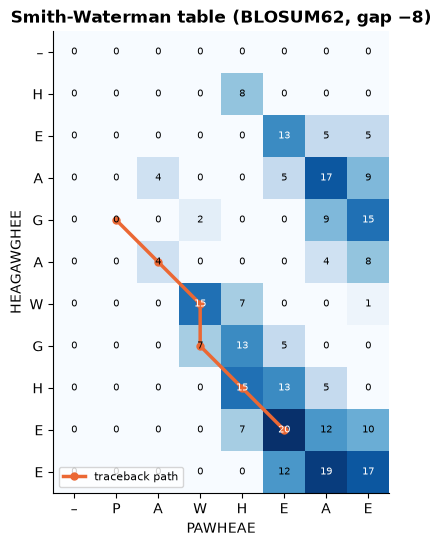

In [6]:
AA = "ARNDCQEGHILKMFPSTWYV"
BLOSUM62_ROWS = """
 4 -1 -2 -2  0 -1 -1  0 -2 -1 -1 -1 -1 -2 -1  1  0 -3 -2  0
-1  5  0 -2 -3  1  0 -2  0 -3 -2  2 -1 -3 -2 -1 -1 -3 -2 -3
-2  0  6  1 -3  0  0  0  1 -3 -3  0 -2 -3 -2  1  0 -4 -2 -3
-2 -2  1  6 -3  0  2 -1 -1 -3 -4 -1 -3 -3 -1  0 -1 -4 -3 -3
 0 -3 -3 -3  9 -3 -4 -3 -3 -1 -1 -3 -1 -2 -3 -1 -1 -2 -2 -1
-1  1  0  0 -3  5  2 -2  0 -3 -2  1  0 -3 -1  0 -1 -2 -1 -2
-1  0  0  2 -4  2  5 -2  0 -3 -3  1 -2 -3 -1  0 -1 -3 -2 -2
 0 -2  0 -1 -3 -2 -2  6 -2 -4 -4 -2 -3 -3 -2  0 -2 -2 -3 -3
-2  0  1 -1 -3  0  0 -2  8 -3 -3 -1 -2 -1 -2 -1 -2 -2  2 -3
-1 -3 -3 -3 -1 -3 -3 -4 -3  4  2 -3  1  0 -3 -2 -1 -3 -1  3
-1 -2 -3 -4 -1 -2 -3 -4 -3  2  4 -2  2  0 -3 -2 -1 -2 -1  1
-1  2  0 -1 -3  1  1 -2 -1 -3 -2  5 -1 -3 -1  0 -1 -3 -2 -2
-1 -1 -2 -3 -1  0 -2 -3 -2  1  2 -1  5  0 -2 -1 -1 -1 -1  1
-2 -3 -3 -3 -2 -3 -3 -3 -1  0  0 -3  0  6 -4 -2 -2  1  3 -1
-1 -2 -2 -1 -3 -1 -1 -2 -2 -3 -3 -1 -2 -4  7 -1 -1 -4 -3 -2
 1 -1  1  0 -1  0  0  0 -1 -2 -2  0 -1 -2 -1  4  1 -3 -2 -2
 0 -1  0 -1 -1 -1 -1 -2 -2 -1 -1 -1 -1 -2 -1  1  5 -2 -2  0
-3 -3 -4 -4 -2 -2 -3 -2 -2 -3 -2 -3 -1  1 -4 -3 -2 11  2 -3
-2 -2 -2 -3 -2 -1 -2 -3  2 -1 -1 -2 -1  3 -3 -2 -2  2  7 -1
 0 -3 -3 -3 -1 -2 -2 -3 -3  3  1 -2  1 -1 -2 -2  0 -3 -1  4
"""
B62 = np.array([[int(v) for v in row.split()] for row in BLOSUM62_ROWS.strip().splitlines()])
assert B62.shape == (20, 20) and (B62 == B62.T).all()            # a substitution matrix is symmetric
BLOSUM62 = {(a, b): int(B62[i, j]) for i, a in enumerate(AA) for j, b in enumerate(AA)}
print(pd.DataFrame(B62, index=list(AA), columns=list(AA)).loc[list("WYFCLI"), list("WYFCLI")])

blosum = lambda a, b: BLOSUM62[(a, b)]
p1, p2 = "HEAGAWGHEE", "PAWHEAE"                  # the classic example from Durbin et al. (1998)
g_sc, g_a, g_b, Fp = nw_align(p1, p2, blosum, -8)
l_sc, l_a, l_b, Hp, path = sw_align(p1, p2, blosum, -8)
print(f"\nglobal (BLOSUM62, gap -8): score {g_sc:.0f}\n  {g_a}\n  {g_b}")
print(f"local  (BLOSUM62, gap -8): score {l_sc:.0f}\n  {l_a}\n  {l_b}")

fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(Hp, cmap="Blues")
pi, pj = zip(*path)
ax.plot(pj, pi, color=PALETTE[1], lw=2.5, marker="o", ms=5, label="traceback path")
ax.set_xticks(range(len(p2) + 1), ["–"] + list(p2)); ax.set_yticks(range(len(p1) + 1), ["–"] + list(p1))
for i in range(Hp.shape[0]):
    for j in range(Hp.shape[1]):
        ax.text(j, i, int(Hp[i, j]), ha="center", va="center", fontsize=7,
                color="white" if Hp[i, j] > Hp.max() * 0.6 else "black")
ax.set(title="Smith-Waterman table (BLOSUM62, gap −8)", xlabel=p2, ylabel=p1); ax.grid(False)
ax.legend(loc="lower left", fontsize=8); plt.show()

**What just happened?** The BLOSUM62 excerpt shows the biology: W–W scores +11 (tryptophan is rare and rarely replaced), similar hydrophobic residues such as I–L score +2, and dissimilar pairs are negative. The local alignment ignores the poorly matching ends and finds the shared core around `AW…HE`. In the heat map, the high-scoring diagonal run is the local alignment; the path starts where the scores rise from 0 and ends at the maximum cell.

> 🎓 **Exam / interview tip:** "Global or local?" Global when the sequences are related along their whole length and of similar size (two versions of the same gene). Local when you search for a shared domain or a short query inside a long sequence (a read inside a genome, a domain inside a protein). Know the three changes NW → SW: borders 0, `max(0, ...)`, trace back from the global maximum to the first 0.

---
## 3. k-mers, Count-Min and MinHash genome distances

> 💬 **In plain English:** cut each genome into all its overlapping short words of length k. Similar genomes share many words, and we can estimate "how many words are shared" from a tiny random sample of them.

**Definitions.**
- The **k-mers** of $s$ are its $n - k + 1$ overlapping substrings of length $k$. The **k-mer spectrum** is their count table. With $4^k$ possible DNA k-mers, $k \approx 16$–$31$ makes almost every k-mer unique in a genome.
- **Count-Min sketch** (see [advanced algorithms 06](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb)): $d$ rows of $w$ counters; each k-mer increments one counter per row; the estimate is the minimum. It never under-counts and over-counts by at most $\varepsilon N$ (with $w = \lceil e/\varepsilon\rceil$) with probability $1 - \delta$ ($d = \lceil\ln(1/\delta)\rceil$). Used by k-mer counters to filter out sequencing errors (k-mers seen once).
- **Jaccard similarity** of two k-mer sets: $J(A, B) = |A\cap B| / |A\cup B|$. **MinHash** estimates it: for a random hash $h$, $P[\min h(A) = \min h(B)] = J$. The **bottom-$s$ sketch** keeps the $s$ smallest hash values of a set; the estimate is the fraction of the $s$ smallest values of $A \cup B$ that lie in both sketches.
- **Mash distance** (Ondov et al., 2016) turns $J$ into an estimate of the per-letter mutation rate, assuming independent substitutions: $D = -\frac{1}{k}\ln\frac{2J}{1+J}$.

**Worked example.** 3-mers of `ACGTAC`: `ACG, CGT, GTA, TAC` (4 = 6 − 3 + 1). For `ACGTTC`: `ACG, CGT, GTT, TTC`. Shared: {ACG, CGT}; union has 6 k-mers, so $J = 2/6 = 0.33$. One substitution destroyed up to $k$ k-mers, which is why $J$ falls fast with mutation and why the Mash formula has $1/k$.

In [7]:
def kmers(s, k):
    return [s[i:i + k] for i in range(len(s) - k + 1)]

def canonical(kmer):
    rc = revcomp(kmer)
    return min(kmer, rc)

assert kmers("ACGTAC", 3) == ["ACG", "CGT", "GTA", "TAC"]
A3, B3 = set(kmers("ACGTAC", 3)), set(kmers("ACGTTC", 3))
print("hand example J =", round(len(A3 & B3) / len(A3 | B3), 3))

# --- 2-bit encoding + a vectorised 64-bit hash, so sketching is fast in numpy
CODE = {"A": 0, "C": 1, "G": 2, "T": 3}
def kmer_codes(s, k):
    """Integer code of every k-mer (2 bits per letter), computed with a sliding window. k <= 31."""
    x = np.array([CODE[c] for c in s], dtype=np.uint64)
    codes = np.zeros(len(s) - k + 1, dtype=np.uint64)
    for j in range(k):                                    # build codes column by column
        codes = (codes << np.uint64(2)) | x[j:len(s) - k + 1 + j]
    return codes

def mix64(v):
    """splitmix64 finaliser: a fast, well-mixed 64-bit hash of integer codes (wraps mod 2^64)."""
    v = np.asarray(v, dtype=np.uint64)
    v = (v ^ (v >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
    v = (v ^ (v >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
    return v ^ (v >> np.uint64(31))

def bottom_sketch(s, k, size):
    h = np.unique(mix64(kmer_codes(s, k)))               # unique hash values, sorted
    return h[:size]

def minhash_jaccard(sa, sb, size):
    union_small = np.union1d(sa, sb)[:size]               # the `size` smallest hashes of A u B
    both = np.intersect1d(sa, sb)
    return np.isin(union_small, both).mean()

def mash_distance(j, k):
    return 1.0 if j == 0 else -np.log(2 * j / (1 + j)) / k

assert np.array_equal(kmer_codes("ACGT", 2), np.array([1, 6, 11], dtype=np.uint64))   # AC=0b0001, CG=0b0110, GT=0b1011

# --- Count-Min sketch over 8-mers of a 50 kb sequence (exact counts for comparison)
genome = random_dna(50_000, gc=0.45)
codes8 = kmer_codes(genome, 8)
exact = Counter(codes8.tolist())
W_, D_ = 2048, 4
seeds = [np.uint64(s_) for s_ in (11, 22, 33, 44)]
cms = np.zeros((D_, W_), dtype=np.int64)
for r_, sd in enumerate(seeds):
    np.add.at(cms[r_], (mix64(codes8 ^ sd) % np.uint64(W_)).astype(np.int64), 1)
keys = np.array(list(exact.keys()), dtype=np.uint64)
est = np.min([cms[r_][(mix64(keys ^ sd) % np.uint64(W_)).astype(np.int64)] for r_, sd in enumerate(seeds)], axis=0)
true = np.array(list(exact.values()))
assert (est >= true).all()                                   # Count-Min never under-counts
N_ = len(codes8); eps_ = math.e / W_
print(f"Count-Min ({D_} x {W_} counters for {len(exact):,} distinct 8-mers): mean over-count {np.mean(est-true):.2f}, "
      f"max {np.max(est-true)}; bound eps*N = {eps_*N_:.0f}; "
      f"fraction within bound {np.mean(est - true <= eps_ * N_):.4f}")

hand example J = 0.333
Count-Min (4 x 2048 counters for 34,241 distinct 8-mers): mean over-count 17.78, max 39; bound eps*N = 66; fraction within bound 1.0000


pair  exact Jaccard  MinHash Jaccard  Mash distance  true fraction of differing letters
 A-B         0.4963            0.483         0.0268                              0.0248
 A-C         0.2390            0.241         0.0591                              0.0574
 A-D         0.1580            0.167         0.0782                              0.0772
 B-C         0.2222            0.229         0.0617                              0.0614
 B-D         0.1477            0.155         0.0822                              0.0810
 C-D         0.3495            0.357         0.0401                              0.0395
sketch size 1000 hashes per genome vs about 59,984 distinct 16-mers


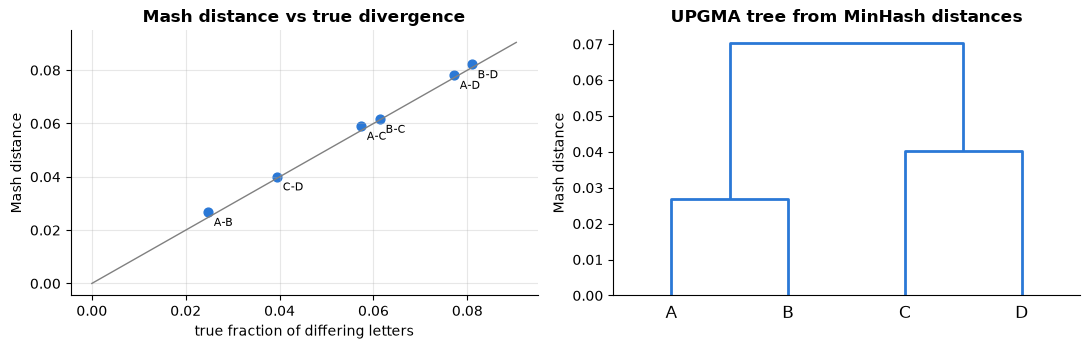

In [8]:
# --- Evolve a small family of genomes along a known tree and recover the tree from MinHash distances
def mutate(s, rate, rng=rng):
    """Independent point substitutions at the given per-letter rate."""
    arr = np.array(list(s))
    hit = rng.random(len(arr)) < rate
    for i in np.flatnonzero(hit):
        arr[i] = rng.choice([b for b in DNA if b != arr[i]])
    return "".join(arr)

K, SKETCH = 16, 1000
root = random_dna(60_000, gc=0.45)
X_ = mutate(root, 0.02); Y_ = mutate(root, 0.02)
genomes = {"A": mutate(X_, 0.01), "B": mutate(X_, 0.015), "C": mutate(Y_, 0.01), "D": mutate(Y_, 0.03)}
names = list(genomes)
sketches = {nm: bottom_sketch(g, K, SKETCH) for nm, g in genomes.items()}
kmer_sets = {nm: set(kmer_codes(g, K).tolist()) for nm, g in genomes.items()}

rows, Dm = [], np.zeros((4, 4))
for (i, a), (j, b) in itertools.combinations(enumerate(names), 2):
    j_exact = len(kmer_sets[a] & kmer_sets[b]) / len(kmer_sets[a] | kmer_sets[b])
    j_mh = minhash_jaccard(sketches[a], sketches[b], SKETCH)
    p_true = np.mean(np.frombuffer(genomes[a].encode(), np.uint8) != np.frombuffer(genomes[b].encode(), np.uint8))
    Dm[i, j] = Dm[j, i] = mash_distance(j_mh, K)
    rows.append({"pair": a + "-" + b, "exact Jaccard": round(j_exact, 4), "MinHash Jaccard": round(j_mh, 4),
                 "Mash distance": round(Dm[i, j], 4), "true fraction of differing letters": round(p_true, 4)})
mash_table = pd.DataFrame(rows)
print(mash_table.to_string(index=False))
print(f"sketch size {SKETCH} hashes per genome vs about {len(kmer_sets['A']):,} distinct 16-mers")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].scatter(mash_table["true fraction of differing letters"], mash_table["Mash distance"], color=PALETTE[0], s=40)
for _, rw in mash_table.iterrows():
    ax[0].annotate(rw["pair"], (rw["true fraction of differing letters"], rw["Mash distance"]), fontsize=8,
                   xytext=(4, -10), textcoords="offset points")
lim = [0, mash_table[["true fraction of differing letters", "Mash distance"]].to_numpy().max() * 1.1]
ax[0].plot(lim, lim, color="gray", lw=1)
ax[0].set(title="Mash distance vs true divergence", xlabel="true fraction of differing letters", ylabel="Mash distance")
dendrogram(linkage(squareform(Dm), method="average"), labels=names, ax=ax[1], color_threshold=0,
           link_color_func=lambda _: PALETTE[0])
ax[1].set(title="UPGMA tree from MinHash distances", ylabel="Mash distance"); ax[1].grid(False)
plt.tight_layout(); plt.show()

**What just happened?**
- The Count-Min sketch never under-counted, and every over-count (mean about 18, maximum 39) stayed below the $\varepsilon N \approx 66$ guarantee, using 8,192 counters for 34,241 distinct 8-mers. Its relative error is large for rare k-mers, which is acceptable when the goal is to find frequent ones or to drop k-mers seen once.
- We evolved four genomes along a known tree: A and B descend from X, C and D from Y. Each genome's 60,000 16-mers were summarised by just **1,000 hash values**, yet the MinHash Jaccard is close to the exact Jaccard, and the Mash distance tracks the true fraction of differing letters (points near the diagonal).
- Average-linkage clustering (UPGMA) of the Mash distances recovers the true tree ((A, B), (C, D)). This is how tools like Mash compare thousands of bacterial genomes in seconds, and the same MinHash idea deduplicates web text for LLM training.

**Complexity:** building a sketch is $O(n)$ hashing plus keeping the $s$ smallest values ($O(n \log s)$ with a heap; we used `np.unique` for simplicity); comparing two sketches is $O(s)$, independent of genome size.

---
## 4. Suffix arrays, the BWT and read mapping

> 💬 **In plain English:** sort all the "tails" of a genome alphabetically once. Afterwards, any word can be found by binary search, like looking up a word in a dictionary, instead of reading the whole genome.

**Definitions** (details and the LCP array in [advanced algorithms 08](../../00_AI_Fundamentals/advanced_algorithms/08_advanced_data_structures.ipynb)).
- The **suffix array** $SA$ of $s\$$ (with a unique smallest end marker `$`) lists the starting positions of all suffixes in sorted order. All occurrences of a pattern $P$ form one **contiguous block** of $SA$, found by two binary searches in $O(|P|\log n)$.
- **Prefix doubling** builds it in $O(n\log^2 n)$ (or $O(n\log n)$ with radix sort): sort by the first 1, 2, 4, … letters using the ranks from the previous round.
- The **Burrows–Wheeler transform** is $BWT[i] = s[SA[i] - 1]$ (the letter before each sorted suffix). With the **FM-index** (counts $C[c]$ and occurrence table $Occ(c, i)$), **backward search** counts occurrences of $P$ in $O(|P|)$ steps, using memory close to the compressed genome. Read aligners such as BWA and Bowtie are built on it.
- **Read mapping:** sequencing machines produce millions of short **reads** (here 40 letters) that must be placed on a reference genome, despite sequencing errors. **Pigeonhole seeding:** split a read into $e + 1$ pieces; if the read has at most $e$ mismatches, at least one piece matches **exactly**, so exact search finds candidate positions that we then verify.

**Worked example:** $s$ = `banana$`. Suffixes sorted: `$` (6), `a$` (5), `ana$` (3), `anana$` (1), `banana$` (0), `na$` (4), `nana$` (2). $SA = [6, 5, 3, 1, 0, 4, 2]$, and $BWT$ = `annb$aa`. The pattern `ana` occupies the block of rows 2–3, so it occurs twice, at positions 3 and 1.

In [9]:
def suffix_array(s):
    """Prefix doubling with numpy lexsort: O(n log^2 n). s should end with a unique smallest '$'."""
    n = len(s)
    rank = np.frombuffer(s.encode(), dtype=np.uint8).astype(np.int64)
    k = 1
    while True:
        second = np.full(n, -1, dtype=np.int64)
        second[:n - k] = rank[k:]                            # rank of the next k letters (-1 if past the end)
        sa = np.lexsort((second, rank))                       # sort by (rank, second)
        key = np.stack([rank[sa], second[sa]], axis=1)
        new = np.zeros(n, dtype=np.int64)
        new[1:] = np.cumsum(np.any(key[1:] != key[:-1], axis=1))
        rank = np.empty(n, dtype=np.int64); rank[sa] = new
        if new[-1] == n - 1:                                  # all ranks distinct: done
            return sa
        k *= 2

def sa_search(s, sa, p):
    """All start positions of pattern p, by two binary searches over the suffix array."""
    lo, hi = 0, len(sa)
    while lo < hi:                                            # first suffix >= p
        mid = (lo + hi) // 2
        if s[sa[mid]:sa[mid] + len(p)] < p: lo = mid + 1
        else: hi = mid
    start, hi = lo, len(sa)
    while lo < hi:                                            # first suffix whose prefix > p
        mid = (lo + hi) // 2
        if s[sa[mid]:sa[mid] + len(p)] <= p: lo = mid + 1
        else: hi = mid
    return np.sort(sa[start:lo])

def bwt_from_sa(s, sa):
    return "".join(s[i - 1] for i in sa)                      # s[-1] is '$' for i = 0

class FMIndex:
    def __init__(self, s, sa):
        self.bwt = bwt_from_sa(s, sa)
        alphabet = sorted(set(s))
        b = np.frombuffer(self.bwt.encode(), np.uint8)
        self.occ = {c: np.r_[0, np.cumsum(b == ord(c))] for c in alphabet}   # Occ(c, i) = count in bwt[:i]
        counts = Counter(s); total = 0; self.C = {}
        for c in alphabet:                                    # C[c] = number of letters smaller than c
            self.C[c] = total; total += counts[c]
    def count(self, p):
        lo, hi = 0, len(self.bwt)
        for c in reversed(p):                                 # backward search, one letter at a time
            if c not in self.C:
                return 0
            lo = self.C[c] + self.occ[c][lo]; hi = self.C[c] + self.occ[c][hi]
            if lo >= hi:
                return 0
        return hi - lo

sa_b = suffix_array("banana$")
print("SA(banana$) =", sa_b.tolist(), "| BWT =", bwt_from_sa("banana$", sa_b),
      "| 'ana' at", sa_search("banana$", sa_b, "ana").tolist())
assert sa_b.tolist() == [6, 5, 3, 1, 0, 4, 2] and bwt_from_sa("banana$", sa_b) == "annb$aa"

# Check against the naive definition on random strings, and FM counts against the suffix array
r = np.random.default_rng(3)
for _ in range(100):
    t = "".join(r.choice(list("ACG"), r.integers(1, 40))) + "$"
    assert suffix_array(t).tolist() == sorted(range(len(t)), key=lambda i: t[i:])
ref = genome + "$"
t0 = time.perf_counter(); sa_g = suffix_array(ref); t_sa = time.perf_counter() - t0
fm = FMIndex(ref, sa_g)
for _ in range(200):
    p = "".join(r.choice(list(DNA), r.integers(1, 9)))
    occ_true = [i for i in range(len(genome) - len(p) + 1) if genome.startswith(p, i)]
    assert sa_search(ref, sa_g, p).tolist() == occ_true and fm.count(p) == len(occ_true)
print(f"suffix array of a {len(genome):,}-letter genome built in {t_sa:.2f} s; "
      "SA search and FM backward search match brute force on 200 random patterns")

SA(banana$) = [6, 5, 3, 1, 0, 4, 2] | BWT = annb$aa | 'ana' at [1, 3]


suffix array of a 50,000-letter genome built in 0.10 s; SA search and FM backward search match brute force on 200 random patterns


In [10]:
# Read mapping with pigeonhole seeds: 300 reads of length 40, each with 0-2 sequencing errors
READ_LEN, N_READS = 40, 300
true_pos = r.integers(0, len(genome) - READ_LEN, N_READS)
n_err = r.choice([0, 1, 2], N_READS, p=[0.5, 0.3, 0.2])
reads = []
for p0, ne in zip(true_pos, n_err):
    rd = list(genome[p0:p0 + READ_LEN])
    for i in r.choice(READ_LEN, ne, replace=False):
        rd[i] = r.choice([b for b in DNA if b != rd[i]])
    reads.append("".join(rd))

def hamming(a, b):
    return sum(x != y for x, y in zip(a, b))

def map_read(read, max_mm=2):
    """Pigeonhole: max_mm+1 seeds, exact SA lookup of each, verify candidates by Hamming distance."""
    L = len(read) // (max_mm + 1)
    cands = set()
    for k_ in range(max_mm + 1):
        seed = read[k_ * L:(k_ + 1) * L]
        for hit in sa_search(ref, sa_g, seed):
            cands.add(int(hit) - k_ * L)                      # where the read would start
    good = [(hamming(read, genome[c:c + len(read)]), c) for c in cands if 0 <= c <= len(genome) - len(read)]
    good = [g_ for g_ in good if g_[0] <= max_mm]
    return min(good)[1] if good else None

exact_only = [len(sa_search(ref, sa_g, rd)) > 0 for rd in reads]
mapped = [map_read(rd) for rd in reads]
res = pd.DataFrame({"errors in read": n_err, "found by exact search": exact_only,
                    "mapped correctly with seeds": [m == p0 for m, p0 in zip(mapped, true_pos)]})
print(res.groupby("errors in read").mean().round(3).to_string())
print("reads per error count:", dict(Counter(n_err.tolist())))

                found by exact search  mapped correctly with seeds
errors in read                                                    
0                                 1.0                          1.0
1                                 0.0                          1.0
2                                 0.0                          1.0
reads per error count: {2: 56, 0: 148, 1: 96}


**What just happened?** Our prefix-doubling suffix array matches the naive "sort all suffixes" definition, and both search methods (binary search on the SA, and FM backward search over the BWT) agree with brute force. Exact search finds only the error-free reads; as soon as a read contains one sequencing error, the exact lookup fails. Splitting each read into 3 seeds of 13 letters guarantees (pigeonhole principle) that a read with at most 2 errors has an error-free seed, so the seed-and-verify mapper places **every** read at its true position.

**Complexity:** building the SA here is $O(n\log^2 n)$; one search $O(|P|\log n)$ with the SA, $O(|P|)$ with the FM-index. Seeding costs one search per seed plus verifying the candidates. Short seeds give many random candidates in a big genome (a 13-mer appears about $n/4^{13}$ times by chance), which is the classic speed/sensitivity trade-off in aligners.

---
## 5. Hidden Markov models: CpG islands and profiles

> 💬 **In plain English:** a genome switches between hidden "modes" (inside or outside a special region). We only see the letters, but different modes prefer different letters, so we can guess the modes from the letters.

**Background.** In vertebrate genomes the dinucleotide CG is rare, except in stretches of a few hundred to a few thousand letters called **CpG islands**, which are rich in C and G and often mark the starts of genes. Finding them is a textbook HMM problem (Durbin et al., ch. 3). We use a simplified two-state version (+ = island, − = background) with different letter frequencies. A recap of HMMs is in [classical AI 09](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) (section 11) and [uncommon models](../04_uncommon_models/01_uncommon_ml_models.ipynb). Here the parameters are known; learning them from unlabelled sequences with EM (Baum–Welch) is covered in [PGM 02: EM, variational inference and sampling](../17_probabilistic_graphical_models/02_em_variational_inference_and_sampling.ipynb).

**Definitions.** An **HMM** has hidden states $z_t$ with transition matrix $A_{kl} = P(z_{t+1} = l \mid z_t = k)$, initial distribution $\pi$, and emissions $B_k(x) = P(x_t = x \mid z_t = k)$.
- **Viterbi** finds the most likely state path $\arg\max_z P(z, x)$ by DP: $v_l(t) = B_l(x_t)\max_k v_k(t-1)A_{kl}$, done in **log space** to avoid underflow.
- **Forward–backward** computes posteriors $P(z_t = k \mid x)$ from $\alpha_k(t) = P(x_{1..t}, z_t = k)$ and $\beta_k(t) = P(x_{t+1..T} \mid z_t = k)$.
- Both are $O(TK^2)$ for $T$ letters and $K$ states.

In [11]:
STATES = ["-", "+"]
EMIT = np.array([[0.30, 0.20, 0.20, 0.30],          # background: A, C, G, T
                 [0.20, 0.30, 0.30, 0.20]])         # CpG island: GC-rich
TRANS = np.array([[1 - 1 / 1000, 1 / 1000],          # background segments ~1000 letters on average
                  [1 / 300, 1 - 1 / 300]])           # islands ~300 letters on average
PI = np.array([0.5, 0.5])

def hmm_sample(T, rng=rng):
    z = np.zeros(T, int); x = np.zeros(T, int)
    z[0] = rng.choice(2, p=PI)
    for t in range(T):
        if t > 0:
            z[t] = rng.choice(2, p=TRANS[z[t - 1]])
        x[t] = rng.choice(4, p=EMIT[z[t]])
    return z, x

def viterbi(x, log_pi, log_A, log_B):
    """Most likely hidden path, in log space. x: int array of symbols."""
    T, K = len(x), len(log_pi)
    V = np.zeros((T, K)); back = np.zeros((T, K), int)
    V[0] = log_pi + log_B[:, x[0]]
    for t in range(1, T):
        cand = V[t - 1][:, None] + log_A                 # cand[k, l] = V(t-1, k) + log A[k, l]
        back[t] = cand.argmax(0)
        V[t] = cand.max(0) + log_B[:, x[t]]
    path = np.zeros(T, int); path[-1] = V[-1].argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path, V[-1].max()

def forward_backward(x, pi, A, B):
    """Scaled forward-backward. Returns posteriors (T x K) and log P(x)."""
    T, K = len(x), len(pi)
    alpha = np.zeros((T, K)); beta = np.ones((T, K)); c = np.zeros(T)
    alpha[0] = pi * B[:, x[0]]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
    for t in range(1, T):
        alpha[t] = (alpha[t - 1] @ A) * B[:, x[t]]
        c[t] = alpha[t].sum(); alpha[t] /= c[t]           # rescale so the numbers never underflow
    for t in range(T - 2, -1, -1):
        beta[t] = A @ (B[:, x[t + 1]] * beta[t + 1]) / c[t + 1]
    post = alpha * beta
    return post / post.sum(1, keepdims=True), np.log(c).sum()

# Verify both algorithms against brute force (enumerate all 2^10 state paths of a short sequence)
z_s, x_s = hmm_sample(10)
best_lp, best_path, total = -np.inf, None, 0.0
for zz in itertools.product([0, 1], repeat=10):
    p = PI[zz[0]] * EMIT[zz[0], x_s[0]]
    for t in range(1, 10):
        p *= TRANS[zz[t - 1], zz[t]] * EMIT[zz[t], x_s[t]]
    total += p
    if np.log(p) > best_lp:
        best_lp, best_path = np.log(p), zz
vp, vlp = viterbi(x_s, np.log(PI), np.log(TRANS), np.log(EMIT))
_, logpx = forward_backward(x_s, PI, TRANS, EMIT)
assert tuple(vp) == best_path and np.isclose(vlp, best_lp) and np.isclose(logpx, np.log(total))
print("Viterbi path and forward log-likelihood match brute force over all 1,024 paths")
print("why log space? 0.25 ** 1000 =", 0.25 ** 1000, "(underflows to zero in float64)")

Viterbi path and forward log-likelihood match brute force over all 1,024 paths
why log space? 0.25 ** 1000 = 0.0 (underflows to zero in float64)


                         method  letter accuracy  island F1  island segments found
     Viterbi (most likely path)            0.980      0.874                      2
       posterior P(+ | x) > 0.5            0.979      0.872                      2
GC in a 100-letter window > 0.5            0.972      0.843                     19
              always background            0.909      0.000                      0
truth: 4 island segments covering 9.1% of the sequence
true islands    (start, end): [(623, 795), (2257, 2276), (3429, 3469), (3526, 3840)]
Viterbi islands (start, end): [(626, 751), (3528, 3826)]


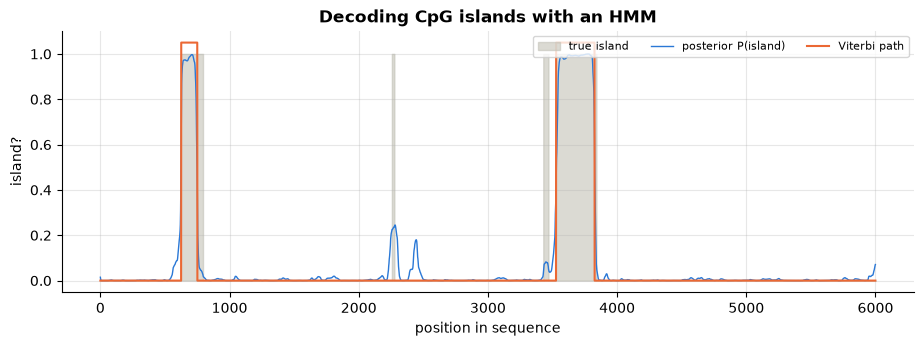

In [12]:
z_true, x_obs = hmm_sample(6000)
path, _ = viterbi(x_obs, np.log(PI), np.log(TRANS), np.log(EMIT))
post, _ = forward_backward(x_obs, PI, TRANS, EMIT)
win = 100                                                   # baseline: GC content in a sliding window
gc_win = np.convolve(np.isin(x_obs, [1, 2]).astype(float), np.ones(win) / win, mode="same")
from sklearn.metrics import f1_score
def n_segments(lab):
    """Number of island segments = number of 0 -> 1 switches (plus one if it starts inside an island)."""
    lab = np.asarray(lab, int)
    return int(lab[0] + np.sum(np.diff(lab) == 1))
preds = {"Viterbi (most likely path)": path,
         "posterior P(+ | x) > 0.5": (post[:, 1] > 0.5).astype(int),
         f"GC in a {win}-letter window > 0.5": (gc_win > 0.5).astype(int),
         "always background": np.zeros_like(z_true)}
rows = [{"method": k, "letter accuracy": accuracy_score(z_true, v), "island F1": f1_score(z_true, v, zero_division=0),
         "island segments found": n_segments(v)} for k, v in preds.items()]
print(pd.DataFrame(rows).round(3).to_string(index=False))
print(f"truth: {n_segments(z_true)} island segments covering {z_true.mean():.1%} of the sequence")
def segments(lab):
    lab = np.r_[0, np.asarray(lab, int), 0]
    return list(zip(np.flatnonzero(np.diff(lab) == 1), np.flatnonzero(np.diff(lab) == -1)))   # [start, end)
print("true islands    (start, end):", [(int(a), int(b)) for a, b in segments(z_true)])
print("Viterbi islands (start, end):", [(int(a), int(b)) for a, b in segments(path)])

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.fill_between(range(len(z_true)), 0, z_true, step="mid", color="#c3c2b7", alpha=0.6, label="true island")
ax.plot(post[:, 1], color=PALETTE[0], lw=1, label="posterior P(island)")
ax.plot(path * 1.05, color=PALETTE[1], lw=1.5, label="Viterbi path")
ax.set(title="Decoding CpG islands with an HMM", xlabel="position in sequence", ylabel="island?")
ax.legend(loc="upper right", fontsize=8, ncol=3); plt.show()

**What just happened?**
- **Letter accuracy is misleading here:** islands cover only about 9% of the sequence, so "always background" already scores 0.91. The island F1 score and the number of segments tell the real story.
- The HMM (Viterbi or posterior) has the best island F1 (0.87 vs 0.84 for the GC window) and, more importantly, returns **2 clean segments** whose boundaries are within a few dozen letters of the true ones. The sliding GC window flickers on and off and reports **19** fragments. The HMM combines **evidence from the letters** with **prior knowledge of segment lengths** (the transition probabilities), so it does not switch state at every local run of C and G.
- Both HMM decoders found the two long islands (172 and 314 letters) and missed the two short ones (19 and 40 letters): with island letters only 60% G/C instead of 40%, a 19-letter stretch is not enough evidence to overcome the cost of switching states. (The posterior does rise to about 0.25 over the 19-letter island, a hint that something is there.) That is a real limitation of HMM segmenters.
- The posterior curve also shows *how sure* the model is near the boundaries. Viterbi gives the single most likely segmentation; posterior decoding maximises the expected number of correctly labelled letters. Both rely on the brute-force-verified algorithms above, run in log space or with scaling: a probability like $0.25^{1000}$ is 0 in floating point.

### Profiles and profile HMMs
A **PWM** (section 1) is a position-specific model of a motif with no gaps. A **profile HMM** (Krogh et al., 1994; the HMMER and Pfam tools) generalises it to whole protein families by adding insertion and deletion states at every position:

```
          I0      I1      I2      I3              I = insert (extra letters)
          ↻       ↻       ↻       ↻               D = delete (skip a position)
  Begin → M1  →   M2  →   M3  → … → End           M = match (position-specific emissions = a PWM column)
           ↘ D1 → ↗ D2 → ↗ D3 ↗
```
Scoring a sequence against a family = Viterbi or forward on this HMM. Below we use the gap-free special case, a **PWM log-odds scan**: score each window $w$ by $\sum_i \log_2 \frac{PWM[i, w_i]}{0.25}$ and report windows above a threshold.

In [13]:
LOGODDS = np.log2(PWM / 0.25)
ONEHOT = {b: np.eye(4)[i] for i, b in enumerate(DNA)}

def pwm_scan(seq, logodds=LOGODDS):
    """Log-odds score of every window of the PWM's width (vectorised with one-hot encoding)."""
    X = np.array([ONEHOT[c] for c in seq])                       # (n, 4)
    L = logodds.shape[0]
    return np.array([(X[i:i + L] * logodds).sum() for i in range(len(seq) - L + 1)])

# 200 sequences of 300 letters; half contain one sampled motif instance
scan_rows = []
for i in range(200):
    sq = random_dna(300)
    has = i % 2 == 0
    if has:
        sq = plant(sq, sample_motif(), int(rng.integers(0, 300 - len(CONSENSUS))))
    scan_rows.append({"has_motif": has, "best_score": pwm_scan(sq).max()})
scan = pd.DataFrame(scan_rows)
print(f"max possible score {LOGODDS.max(1).sum():.1f} bits; "
      f"AUC of 'best window score' for detecting the motif: {roc_auc_score(scan.has_motif, scan.best_score):.3f}")
print(scan.groupby("has_motif")["best_score"].describe()[["mean", "min", "max"]].round(2).to_string())

max possible score 19.0 bits; AUC of 'best window score' for detecting the motif: 0.936
            mean   min    max
has_motif                    
False       4.49 -1.05  16.39
True       13.01  2.12  18.97


**What just happened?** The best-window log-odds score separates sequences with the motif from random ones very well (the AUC is printed above). It is not perfect: some planted instances are weak samples of a fuzzy motif, and a 300-letter random sequence has about 290 windows, so by chance one of them can score fairly high. This multiple-testing effect is why tools report **E-values** (expected number of chance hits of that score in a database of that size).

---
## 6. Sequence classification: k-mers + logistic regression vs a 1-D CNN

> 💬 **In plain English:** decide whether a DNA snippet contains a "switch" (the motif). Option one: count short words and feed the counts to a linear model. Option two: let a small neural network slide learnable "magnifying glasses" along the sequence.

**Task.** 3,000 sequences of 100 letters. Positives contain one sampled motif instance at a random position. To make it non-trivial, negatives contain a **decoy**: the same motif letters, **shuffled**, so the letter composition is identical and only the order differs.

**Two models.**
- **k-mer bag-of-words** (like bag-of-words in [text classification](../../07_NLP/03_text_classification.ipynb)): count every k-mer for $k = 3, 4, 5$ ($64 + 256 + 1024$ features) and fit an L2-regularised logistic regression. Position-invariant, but sees only short words.
- **1-D CNN** (cf. DeepBind, Alipanahi et al., 2015): one-hot input $(4 \times 100)$ → `Conv1d` with 16 filters of width 12 → ReLU → **global max pooling** (position-invariant "is the pattern anywhere?") → linear output. A first-layer filter is a learnable PWM.

In [14]:
def make_dataset(n, length=100, seed=0):
    r_ = np.random.default_rng(seed)
    seqs, ys = [], []
    for i in range(n):
        s_ = random_dna(length, rng=r_)
        m_ = sample_motif(rng=r_)
        y_ = int(i % 2 == 0)
        ins = m_ if y_ else "".join(r_.permutation(list(m_)))      # decoy: same letters, shuffled
        s_ = plant(s_, ins, int(r_.integers(0, length - len(m_))))
        seqs.append(s_); ys.append(y_)
    return seqs, np.array(ys)

seqs, y = make_dataset(3000)
idx = rng.permutation(3000); tr, va, te = idx[:2000], idx[2000:2500], idx[2500:]

ALL_K = [3, 4, 5]
VOCAB = {km: i for i, km in enumerate("".join(p) for k in ALL_K for p in itertools.product(DNA, repeat=k))}
def kmer_counts(seq):
    v = np.zeros(len(VOCAB))
    for k in ALL_K:
        for km in kmers(seq, k):
            v[VOCAB[km]] += 1
    return v
Xk = np.array([kmer_counts(s_) for s_ in seqs])

best = None
for C in (0.001, 0.01, 0.1, 1.0):                                  # choose C on the validation set
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000))
    lr.fit(Xk[tr], y[tr])
    auc = roc_auc_score(y[va], lr.predict_proba(Xk[va])[:, 1])
    if best is None or auc > best[0]:
        best = (auc, C, lr)
auc_va_lr, C_best, lr = best
p_lr = lr.predict_proba(Xk[te])[:, 1]
print(f"k-mer logistic regression: best C = {C_best}, validation AUC {auc_va_lr:.3f}, "
      f"test AUC {roc_auc_score(y[te], p_lr):.3f}, test accuracy {accuracy_score(y[te], p_lr > 0.5):.3f}")
inv = {i: km for km, i in VOCAB.items()}
coef = lr[-1].coef_[0]
print("most positive k-mers:", [inv[i] for i in np.argsort(-coef)[:8]])

k-mer logistic regression: best C = 0.001, validation AUC 0.811, test AUC 0.819, test accuracy 0.742
most positive k-mers: ['TGACG', 'CGTCA', 'CATGC', 'ACGTC', 'GACGT', 'CAAGC', 'TGAC', 'GACG']


In [15]:
def one_hot(seqs_):
    X = np.zeros((len(seqs_), 4, len(seqs_[0])), dtype=np.float32)
    for n_, s_ in enumerate(seqs_):
        X[n_, [CODE[c] for c in s_], np.arange(len(s_))] = 1.0
    return torch.from_numpy(X)

class MotifCNN(nn.Module):
    def __init__(self, n_filters=16, width=12):
        super().__init__()
        self.conv = nn.Conv1d(4, n_filters, kernel_size=width)    # each filter = a learnable PWM
        self.out = nn.Linear(n_filters, 1)
    def forward(self, x):
        h = torch.relu(self.conv(x))                               # (batch, filters, positions)
        h = h.max(dim=2).values                                    # global max pool: anywhere in the sequence
        return self.out(h).squeeze(1)

Xoh = one_hot(seqs); yt = torch.tensor(y, dtype=torch.float32)
torch.manual_seed(0)
cnn = MotifCNN()
opt = torch.optim.Adam(cnn.parameters(), lr=0.01, weight_decay=1e-4)
lossf = nn.BCEWithLogitsLoss()
hist = []
t0 = time.perf_counter()
for epoch in range(25):
    cnn.train()
    for b in torch.randperm(len(tr)).split(64):
        bi = torch.as_tensor(tr)[b]
        opt.zero_grad(); loss = lossf(cnn(Xoh[bi]), yt[bi]); loss.backward(); opt.step()
    cnn.eval()
    with torch.no_grad():
        hist.append({"epoch": epoch + 1, "train loss": lossf(cnn(Xoh[tr]), yt[tr]).item(),
                     "val AUC": roc_auc_score(y[va], cnn(Xoh[va]).numpy())})
with torch.no_grad():
    p_cnn = torch.sigmoid(cnn(Xoh[te])).numpy()
print(f"CNN trained in {time.perf_counter()-t0:.1f} s; final val AUC {hist[-1]['val AUC']:.3f}; "
      f"test AUC {roc_auc_score(y[te], p_cnn):.3f}, test accuracy {accuracy_score(y[te], p_cnn > 0.5):.3f}")

# The PWM scan from section 5 knows the true motif: an "oracle" upper reference
p_pwm = np.array([pwm_scan(seqs[i]).max() for i in te])
clf_table = pd.DataFrame({
    "model": ["k-mer (3,4,5) logistic regression", "1-D CNN (16 filters x 12)", "oracle PWM scan (knows the motif)"],
    "test AUC": [roc_auc_score(y[te], p_lr), roc_auc_score(y[te], p_cnn), roc_auc_score(y[te], p_pwm)],
}).round(3)
print(clf_table.to_string(index=False))

CNN trained in 6.7 s; final val AUC 0.951; test AUC 0.951, test accuracy 0.888


                            model  test AUC
k-mer (3,4,5) logistic regression     0.819
        1-D CNN (16 filters x 12)     0.951
oracle PWM scan (knows the motif)     0.973


most important filter #6: best correlation with the true PWM = 0.93 (shift -1, strand +)
filter consensus (argmax per column): TTGACGTCATGC | true consensus: TGACGTCATGCA


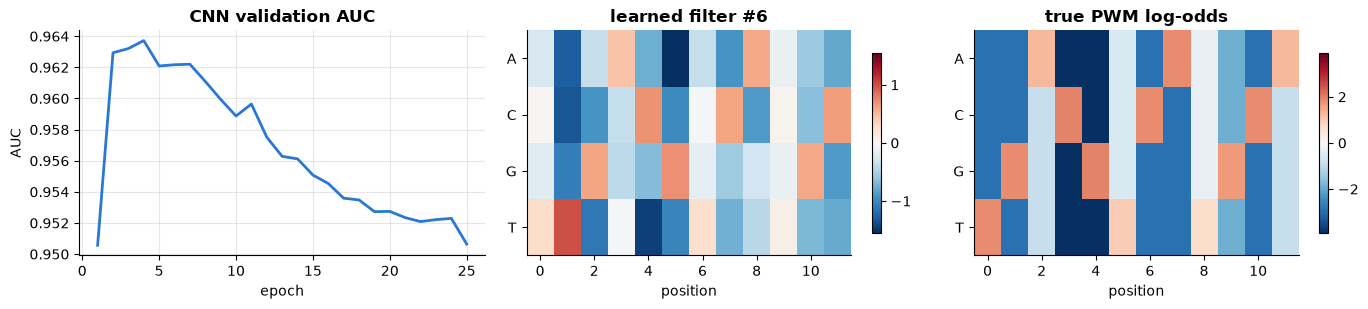

In [16]:
# Which CNN filter matters most, and does it look like the planted motif?
W = cnn.conv.weight.detach().numpy()                     # (filters, 4, width)
importance = cnn.out.weight.detach().numpy()[0]
f_best = int(np.argmax(importance))
filt = W[f_best]
def best_match(filt, logodds):
    """Best correlation between a filter (4 x w) and the PWM log-odds over small shifts and both strands."""
    P = logodds.T                                                   # (4, motif length)
    L = P.shape[1]
    out = []
    for strand, F_ in (("+", filt), ("-", filt[::-1, ::-1])):      # reverse complement: flip letters and positions
        for sh in range(-4, 5):                                     # filter column j  <->  PWM column j + sh
            j0, j1 = max(0, -sh), min(L, L - sh)
            a, b = F_[:, j0:j1], P[:, j0 + sh:j1 + sh]
            out.append((np.corrcoef(a.ravel(), b.ravel())[0, 1], sh, strand))
    return max(out)
corr, shift, strand = best_match(filt, LOGODDS)
print(f"most important filter #{f_best}: best correlation with the true PWM = {corr:.2f} (shift {shift}, strand {strand})")
print("filter consensus (argmax per column):", "".join(DNA[i] for i in filt.argmax(0)), "| true consensus:", CONSENSUS)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
pd.DataFrame(hist).plot(x="epoch", y="val AUC", ax=ax[0], color=PALETTE[0], legend=False)
ax[0].set(title="CNN validation AUC", ylabel="AUC")
for a, M, title in [(ax[1], filt, f"learned filter #{f_best}"), (ax[2], LOGODDS.T, "true PWM log-odds")]:
    lim_ = np.abs(M).max()
    im = a.imshow(M, cmap="RdBu_r", vmin=-lim_, vmax=lim_, aspect="auto")
    a.set_yticks(range(4), list(DNA)); a.set(title=title, xlabel="position"); a.grid(False)
    plt.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()

**What just happened?**
- The **k-mer model** cannot see the whole 12-letter motif: its features are words of length ≤ 5, and because the decoy has exactly the same letters, it must rely on short ordered fragments of the motif. It works, but it is limited (and the most positive k-mers are pieces of the consensus `TGACGTCATGCA`).
- The **CNN** learns 12-letter filters directly. Its test AUC is much higher (0.95 vs 0.82), and it comes close to the **oracle** PWM scan (0.97), which was given the true motif. Its validation AUC peaked after about 4 epochs and then drifted down slightly: mild overfitting on 2,000 sequences. In practice you would keep the checkpoint with the best validation score (early stopping).
- The most important filter correlates with the true PWM log-odds and its consensus resembles the planted motif (possibly shifted, or on the reverse strand). This is the classic way to **interpret** genomics CNNs: first-layer filters ≈ motifs. Compare the two heat maps: red cells (positive weights) sit on the consensus letters.

**Complexity:** k-mer features $O(nL)$ per sequence; the CNN costs $O(F \cdot w \cdot 4 \cdot L)$ per sequence for $F$ filters of width $w$.

> ⚠️ **Common mistake:** splitting **related** sequences (the same gene from close species, overlapping windows of one chromosome) across train and test. The model then recognises near-copies and looks far better than it is, the sequence version of spatial leakage. Split by gene family or by chromosome, and cluster sequences by identity first (as protein benchmarks do).

---
## 7. Embedding and clustering sequences; protein language models

> 💬 **In plain English:** turn every protein into a vector so that relatives end up close together, then group them. Big "protein language models" do the same with far richer vectors, learned by filling in hidden letters.

We simulate 5 protein **families**: each starts from a random ancestor of 150 amino acids; 40 members per family get 30% random substitutions and a few insertions/deletions. The question: can we recover the families without alignment?

- **Composition embedding:** 1-mer (20-d) or 2-mer (400-d) amino-acid frequencies, standardised, then PCA and k-means.
- Families are then evaluated with the **adjusted Rand index (ARI)**: 1 = perfect, 0 = chance.

                             embedding  ARI vs true families
 1-mer composition (20 dims) -> PCA 10                 0.881
2-mer composition (400 dims) -> PCA 10                 1.000


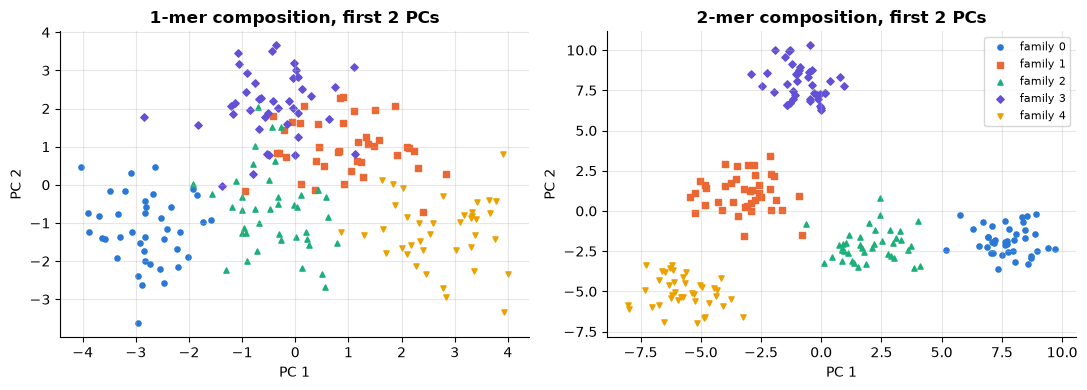

In [17]:
def mutate_protein(s, sub_rate, n_indel, rng=rng):
    arr = list(s)
    for i in range(len(arr)):
        if rng.random() < sub_rate:
            arr[i] = AA[rng.integers(20)]
    for _ in range(n_indel):
        i = int(rng.integers(len(arr)))
        if rng.random() < 0.5:
            del arr[i]
        else:
            arr.insert(i, AA[rng.integers(20)])
    return "".join(arr)

N_FAM, PER_FAM = 5, 40
fam_seqs, fam_lab = [], []
for f in range(N_FAM):
    anc = "".join(rng.choice(list(AA), 150))
    for _ in range(PER_FAM):
        fam_seqs.append(mutate_protein(anc, 0.30, 3)); fam_lab.append(f)
fam_lab = np.array(fam_lab)

AA2 = ["".join(p) for p in itertools.product(AA, repeat=2)]
def composition(seq, k):
    vocab = AA if k == 1 else AA2
    c = Counter(kmers(seq, k))
    v = np.array([c[w] for w in vocab], float)
    return v / v.sum()

rows = []
emb = {}
for k in (1, 2):
    Xc = StandardScaler().fit_transform(np.array([composition(s_, k) for s_ in fam_seqs]))
    Z = PCA(n_components=10, random_state=0).fit_transform(Xc)
    lab = KMeans(N_FAM, n_init=10, random_state=0).fit_predict(Z)
    emb[k] = Z
    rows.append({"embedding": f"{k}-mer composition ({20**k} dims) -> PCA 10", "ARI vs true families": round(adjusted_rand_score(fam_lab, lab), 3)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
mk = ["o", "s", "^", "D", "v"]; fam_cols = [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[6], PALETTE[3]]
for a, k in zip(ax, (1, 2)):
    for f in range(N_FAM):
        m_ = fam_lab == f
        a.scatter(emb[k][m_, 0], emb[k][m_, 1], s=14, marker=mk[f], color=fam_cols[f], label=f"family {f}")
    a.set(title=f"{k}-mer composition, first 2 PCs", xlabel="PC 1", ylabel="PC 2")
ax[1].legend(fontsize=8, loc="best"); plt.tight_layout(); plt.show()

**What just happened?** Even single amino-acid frequencies (1-mers) separate most families (ARI 0.88): each random ancestor has its own chance composition, and its descendants inherit it, but the clusters overlap. **2-mer** frequencies also keep **order** information (which letter follows which); about half of each ancestor's 2-mers survive 30% substitution ($0.7^2 \approx 0.49$), so family members share many of them, the families separate cleanly, and k-means recovers them perfectly (ARI 1.0). This is alignment-free comparison, the same idea as the k-mer sets of section 3.

### Protein language models (concept)
A **protein language model** (pLM) is a Transformer ([architecture](../../05_Deep_Learning/05_transformers_architecture.ipynb), [how LLMs work](../../08_LLM/00_start_here_how_llms_work.ipynb)) trained on hundreds of millions of natural protein sequences with **masked-token prediction**: hide 15% of the amino acids and predict them from the rest. To succeed it must learn which residues co-vary across evolution, which reflects 3-D contacts and function. Its hidden states are **embeddings** used for structure prediction, function annotation and the effect of mutations.

| model | year | what it does |
|---|---|---|
| AlphaFold2 (DeepMind) | 2021 | structure from sequence + multiple sequence alignments; near-experimental accuracy in CASP14 |
| ESM-2 / ESMFold (Meta) | 2022–23 | pLM up to 15B parameters; ESMFold predicts structure from a single sequence |
| AlphaFold 3 | 2024 | complexes of proteins, DNA/RNA, ligands, with a diffusion-based structure module |
| ESM3 (EvolutionaryScale) | 2024–25 | generative multimodal model over sequence, structure and function |
| DNA LMs: DNABERT, Nucleotide Transformer, Evo / Evo 2 | 2021–25 | the same idea on DNA, with long contexts for whole genes and genomes |

The 2024 Nobel Prize in Chemistry went to David Baker (computational protein design) and to Demis Hassabis and John Jumper (AlphaFold).

Below is a **toy** version of masked prediction: predict a hidden amino acid from its left and right neighbours using counts from *other* family members. Because relatives share context, even this simple "model" beats guessing, a tiny echo of why pLMs work.

In [18]:
# Toy masked-residue prediction: context (left, right) -> most frequent middle letter, learned from training proteins
fam_idx = rng.permutation(len(fam_seqs)); tr_p, te_p = fam_idx[:160], fam_idx[160:]
ctx_counts, mid_counts = {}, Counter()
for i in tr_p:
    s_ = fam_seqs[i]
    for t in range(1, len(s_) - 1):
        ctx_counts.setdefault((s_[t - 1], s_[t + 1]), Counter())[s_[t]] += 1
        mid_counts[s_[t]] += 1
most_common = mid_counts.most_common(1)[0][0]
hits_ctx = hits_base = n_ = 0
for i in te_p:
    s_ = fam_seqs[i]
    for t in rng.choice(np.arange(1, len(s_) - 1), 30, replace=False):    # mask 30 random positions
        c = ctx_counts.get((s_[t - 1], s_[t + 1]))
        guess = c.most_common(1)[0][0] if c else most_common
        hits_ctx += guess == s_[t]; hits_base += most_common == s_[t]; n_ += 1
print(f"masked-residue accuracy on {n_} hidden positions: context model {hits_ctx/n_:.1%} "
      f"vs most-frequent-letter baseline {hits_base/n_:.1%} (random guess = 5%)")

masked-residue accuracy on 1200 hidden positions: context model 20.8% vs most-frequent-letter baseline 6.3% (random guess = 5%)


**What just happened?** The context model is right about 21% of the time, more than three times the 6% baseline, because the training set contains relatives of each test protein: a (left, right) context from the same family position usually predicts the right middle letter. Real pLMs replace this lookup table with a deep Transformer that uses the **whole** sequence as context and generalises across families, but the training signal is the same: fill in the blanks.

---
## 8. Data ethics for genomic data

> 💬 **In plain English:** your DNA is shared with your relatives, it cannot be changed like a password, and it can identify you even when your name is removed. Treat it as the most sensitive data there is.

**Key points** (see also [research ethics](../../24_Research_Methods/01_research_methodology_and_literature_review.ipynb) section 8, [privacy in ML](../../19_AI_Ethics_and_Safety/03_privacy.ipynb) and [privacy and security](../../00_AI_Fundamentals/04_privacy_and_security.ipynb)):
- **Identifiability.** "Anonymous" genomes can be re-identified: Gymrek et al. (2013) inferred surnames of anonymous research participants from Y-chromosome markers and public genealogy databases; investigators have identified suspects through relatives in consumer genealogy databases (the 2018 Golden State Killer case).
- **Aggregate statistics leak too.** Homer et al. (2008) showed that one can tell whether a person's DNA is part of a mixture, or a study, from **published allele frequencies**. After this, the NIH moved aggregate genome-wide association data behind controlled access. We reproduce the idea below with synthetic data.
- **Consent and governance.** Broad vs specific consent, the right to withdraw, return of incidental findings, and community engagement (the HeLa cell line was taken from Henrietta Lacks in 1951 without consent; in 2013 the NIH reached an agreement with her family on access to the HeLa genome). Data access committees and controlled-access archives (dbGaP, EGA) and GA4GH standards govern sharing.
- **Law.** The EU GDPR lists genetic data as a **special category** (Article 9); in the US, HIPAA covers health providers, and GINA (2008) bans genetic discrimination in health insurance and employment (but not life insurance). Rules differ between countries, so check local law and your institution's ethics board.
- **Consumer genomics.** A 2023 credential-stuffing attack on 23andMe exposed data of millions of users through its relative-matching feature, and the company's 2025 bankruptcy raised the question of what happens to customers' genomes when a company is sold.
- **Fairness.** Most genomic studies over-represent people of European ancestry, so risk scores and models can be much less accurate for others. Report the ancestry make-up of your data and evaluate per group.

 SNPs published  membership AUC
            100           0.715
           1000           0.933
           5000           1.000
          20000           1.000


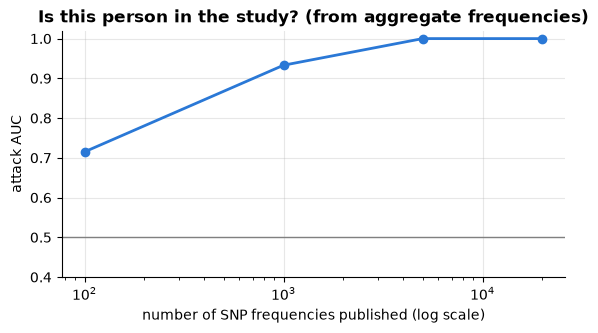

In [19]:
# Membership inference from published allele frequencies (the idea of Homer et al., 2008), synthetic genotypes
def genotypes(freqs, n, rng=rng):
    """n individuals x m SNPs; each value is the allele dosage / 2 in {0, 0.5, 1}."""
    return rng.binomial(2, freqs, size=(n, len(freqs))) / 2

M_SNP = 20_000
p_pop = rng.uniform(0.05, 0.5, M_SNP)                         # population allele frequencies
study = genotypes(p_pop, 100)                                 # the 100 people in a study
reference = genotypes(p_pop, 200)                             # a public reference panel
outsiders = genotypes(p_pop, 100)                             # people NOT in the study
published = study.mean(0)                                     # the "harmless" aggregate the study publishes
ref_freq = reference.mean(0)

def homer_stat(Y, n_snps):
    """Sum over SNPs of |Y - ref| - |Y - published|: positive => Y looks closer to the study mix."""
    d = np.abs(Y[:, :n_snps] - ref_freq[:n_snps]) - np.abs(Y[:, :n_snps] - published[:n_snps])
    return d.sum(1) / np.sqrt(n_snps)

rows = []
for m_ in (100, 1000, 5000, 20_000):
    s_in, s_out = homer_stat(study, m_), homer_stat(outsiders, m_)
    auc = roc_auc_score(np.r_[np.ones(100), np.zeros(100)], np.r_[s_in, s_out])
    rows.append({"SNPs published": m_, "membership AUC": round(auc, 3)})
mi = pd.DataFrame(rows)
print(mi.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(mi["SNPs published"], mi["membership AUC"], marker="o", color=PALETTE[0])
ax.axhline(0.5, color="gray", lw=1)
ax.set(xscale="log", ylim=(0.4, 1.02), title="Is this person in the study? (from aggregate frequencies)",
       xlabel="number of SNP frequencies published (log scale)", ylabel="attack AUC")
plt.show()

**What just happened?** The study published only **averages** over 100 people, which sounds anonymous. Yet a person who took part pulls each average slightly towards their own genotype. One SNP reveals almost nothing, but summing this tiny bias over many SNPs gives a strong test of membership: AUC 0.72 with 100 SNPs, 0.93 with 1,000 and a perfect 1.00 from 5,000 SNPs (real arrays measure hundreds of thousands to millions). If the study is about a disease, membership itself is sensitive information. Defences: controlled access to summary statistics, publishing fewer or noisier statistics (**differential privacy**), and data-use agreements. The same attack family, **membership inference**, applies to ML models trained on any personal data.

---
## 9. Summary table

> 💬 **In plain English:** the main tools and when to use each.

| Problem | Method | Time | Notes |
|---|---|---|---|
| global similarity of two sequences | Needleman–Wunsch | $O(nm)$ | linear-space score; Hirschberg for the alignment |
| shared region / domain | Smith–Waterman | $O(nm)$ | `max(0, …)`, trace back from the best cell |
| database search | BLAST (seed and extend) | heuristic, near-linear | E-values for significance |
| genome-scale similarity | k-mer sets + MinHash (Mash) | $O(n)$ sketch, $O(s)$ compare | alignment-free, scales to millions of genomes |
| k-mer frequencies under memory limits | Count-Min sketch | $O(d)$ per k-mer | over-counts only |
| exact substring / motif search | suffix array; FM-index on BWT | $O(\lvert P\rvert\log n)$; $O(\lvert P\rvert)$ | read aligners (BWA, Bowtie) |
| reads with errors | pigeonhole seeds + verification | seeds × hits | speed vs sensitivity |
| segmentation (islands, genes) | HMM + Viterbi / posterior | $O(TK^2)$ | log space or scaling |
| motif / family scoring | PWM; profile HMM (HMMER) | $O(nL)$; $O(nL)$ | E-values for multiple testing |
| sequence → label | k-mer BoW + LR; 1-D CNN; pLM embeddings | linear; $O(FwL)$; Transformer | split by family to avoid leakage |

## 🔗 How this connects to modern AI

- **Dynamic programming everywhere.** Needleman–Wunsch is edit distance ([dsa/09](../../00_AI_Fundamentals/dsa/09_dynamic_programming.ipynb)), used to score speech recognition (word error rate) and OCR; Viterbi decodes HMMs and CRFs in tagging ([NER](../../07_NLP/04_named_entity_recognition.ipynb)); beam search in LLM decoding is an approximate version of the same "best path" search that Viterbi solves exactly for HMMs.
- **Sketches and suffix arrays for LLM data.** MinHash-LSH deduplicates web-scale training corpora, and suffix arrays find exact repeated substrings (Lee et al., 2021) or count n-grams over trillions of tokens (Infini-gram, 2024), the same tools as sections 3–4 ([advanced algorithms 06](../../00_AI_Fundamentals/advanced_algorithms/06_streaming_and_sketching_algorithms.ipynb), [08](../../00_AI_Fundamentals/advanced_algorithms/08_advanced_data_structures.ipynb)).
- **CNNs and Transformers on DNA.** DeepBind (2015) and DeepSEA learned motifs with 1-D CNNs like ours; Enformer (2021) predicts gene expression from 200 kb of sequence with a Transformer; DeepVariant (2018) calls genetic variants with an image CNN; AlphaMissense (2023) scores the effect of every possible single amino-acid change.
- **Language models of life.** ESM-2/ESM3, AlphaFold 2/3 and DNA models such as Evo 2 apply masked or autoregressive language modelling to biological sequences (section 7), the same recipe as [LLMs](../../08_LLM/00_start_here_how_llms_work.ipynb); embeddings feed [vector search](../../22_ML_System_Design/05_vector_databases.ipynb) over protein databases.
- **Probabilistic models.** Profile HMMs and the forward algorithm are instances of the probabilistic graphical models in [classical AI 09](../../00_AI_Fundamentals/classical_ai/09_uncertain_knowledge_and_reasoning.ipynb) (treated in depth, with exact inference on chains and trees, in [PGM 01: Markov networks and exact inference](../17_probabilistic_graphical_models/01_markov_networks_and_exact_inference.ipynb)); medical imaging is covered in [CV 10](../../06_Computer_Vision/10_medical_image_analysis.ipynb).
- **Privacy.** The membership attack in section 8 is the ancestor of membership-inference attacks on ML models and a key motivation for differential privacy ([privacy](../../19_AI_Ethics_and_Safety/03_privacy.ipynb)).

## Recap
- DNA/protein are strings over 4/20 letters; remember both strands (reverse complement) and the genetic code (64 codons → 20 amino acids + 3 stops).
- Motifs are fuzzy: describe them with a **PWM**; information content measures how strict each position is.
- **Needleman–Wunsch** (global) and **Smith–Waterman** (local) are $O(nm)$ DPs; SW adds `max(0, …)` and traces back from the best cell. BLOSUM62 scores protein substitutions; affine gaps need three matrices (Gotoh).
- **k-mers** enable alignment-free methods: Count-Min for counts, **MinHash** for Jaccard, **Mash distance** $-\frac1k\ln\frac{2J}{1+J}$ for divergence, enough to rebuild a tree.
- **Suffix arrays** and the **FM-index/BWT** give fast exact search; **pigeonhole seeds** handle reads with errors.
- **HMMs** decode hidden segments (CpG islands) with **Viterbi** or **posterior** decoding, in log space; profile HMMs add insert/delete states to PWMs.
- A **1-D CNN** with global max pooling learns motifs as filters and beats a short-k-mer bag-of-words when order matters; split by family to avoid leakage.
- **pLMs** learn from masked-residue prediction; their embeddings power structure and function prediction.
- Genomic data is identifying, shared with relatives and permanent; even **aggregate statistics** leak membership. Consent, controlled access and privacy techniques are part of the job.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy)** Give the reverse complement and GC content of `ATGCGTTA`, and translate `ATGTTTGGCTGA`.

<details><summary>Show solution</summary>

Reverse complement: complement `TACGCAAT`, reversed: `TAACGCAT`. GC content: G, C, G = 3 of 8 = 0.375. Translation: `ATG` M, `TTT` F, `GGC` G, `TGA` stop → `MFG`.

</details>

**2. (Easy, by hand)** Fill the Needleman–Wunsch table for `GA` vs `GTA` (match +1, mismatch −1, gap −1). What is the score and the alignment?

<details><summary>Show solution</summary>

| | – | G | T | A |
|---|---|---|---|---|
| – | 0 | −1 | −2 | −3 |
| G | −1 | 1 | 0 | −1 |
| A | −2 | 0 | 0 | **1** |

Score 1: `G-A` / `GTA` (two matches, one gap: 1 + 1 − 1 = 1).

</details>

**3. (Medium, conceptual)** Why must Viterbi be computed in log space (or with scaling) for real genomes? What goes wrong otherwise, and why does log space turn products into something cheaper?

<details><summary>Show solution</summary>

A path probability is a product of thousands of numbers below 1; $0.25^{1000} \approx 10^{-602}$, far below the smallest positive float64 (about $10^{-308}$, or $5 \times 10^{-324}$ for subnormals), so every path would become 0 and the argmax would be meaningless. Logs turn the product into a sum of moderate negative numbers, and since log is monotone, $\arg\max$ is unchanged. Forward–backward needs sums of probabilities, so it uses scaling (as in our code) or log-sum-exp instead.

</details>

**4. (Medium, coding)** Count **canonical** k-mers, so that a sequence and its reverse complement give identical counts.

<details><summary>Show solution</summary>

```python
from collections import Counter

def revcomp(s):
    return s.translate(str.maketrans("ACGT", "TGCA"))[::-1]

def canonical_kmer_counts(seq, k):
    """Count k-mers on both strands at once: each k-mer is stored as min(kmer, reverse complement)."""
    c = Counter()
    for i in range(len(seq) - k + 1):
        km = seq[i:i + k]
        c[min(km, revcomp(km))] += 1
    return c
```
Tested on 100 random sequences: counts for `s` and `revcomp(s)` are identical.

</details>

**5. (Medium, conceptual)** Two bacterial genomes have a MinHash Jaccard of 0.30 with $k = 21$. Estimate their per-letter divergence with the Mash formula. Why does a larger $k$ make $J$ drop faster for the same divergence?

<details><summary>Show solution</summary>

$D = -\frac{1}{21}\ln\frac{2 \times 0.30}{1.30} = -\frac{1}{21}\ln 0.4615 \approx 0.0368$, about 3.7% of letters differ. A k-mer survives only if all $k$ of its letters are unchanged, probability $(1 - d)^k$, so longer k-mers are destroyed more easily by the same mutation rate. Larger $k$ is more specific (fewer chance matches between unrelated genomes) but saturates sooner for distant genomes.

</details>

**6. (Hard, coding)** Implement global alignment with **affine gap** costs (Gotoh), returning the optimal score. Check it against exhaustive search.

<details><summary>Show solution</summary>

```python
import numpy as np

def global_affine(x, y, match=1, mismatch=-1, gap_open=-3, gap_extend=-1):
    """Gotoh's global alignment score with affine gaps: a gap of length L costs gap_open + (L-1)*gap_extend.
    M = ends with a match/mismatch column, X = ends with a gap in y, Y = ends with a gap in x."""
    n, m = len(x), len(y)
    NEG = -1e18
    M = np.full((n + 1, m + 1), NEG); X = np.full((n + 1, m + 1), NEG); Y = np.full((n + 1, m + 1), NEG)
    M[0, 0] = 0
    for i in range(1, n + 1):
        X[i, 0] = gap_open + (i - 1) * gap_extend
    for j in range(1, m + 1):
        Y[0, j] = gap_open + (j - 1) * gap_extend
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            s = match if x[i - 1] == y[j - 1] else mismatch
            M[i, j] = s + max(M[i - 1, j - 1], X[i - 1, j - 1], Y[i - 1, j - 1])
            X[i, j] = max(M[i - 1, j] + gap_open, X[i - 1, j] + gap_extend, Y[i - 1, j] + gap_open)
            Y[i, j] = max(M[i, j - 1] + gap_open, Y[i, j - 1] + gap_extend, X[i, j - 1] + gap_open)
    return max(M[n, m], X[n, m], Y[n, m])
```
Three matrices track how the alignment ends (match column, gap in `y`, gap in `x`), so opening a gap costs `gap_open` and continuing costs `gap_extend`. Tested against exhaustive enumeration of all alignments on 150 random short pairs with random penalties. Time stays $O(nm)$.

</details>

**7. (Hard, coding)** Find the **longest repeated substring** of a DNA string with a suffix array and the LCP array (Kasai's algorithm).

<details><summary>Show solution</summary>

```python
def lcp_kasai(s, sa):
    """LCP[i] = longest common prefix of suffixes sa[i-1] and sa[i] (LCP[0] = 0), in O(n)."""
    n = len(s)
    rank = [0] * n
    for i, p in enumerate(sa):
        rank[p] = i
    lcp, h = [0] * n, 0
    for p in range(n):
        if rank[p] > 0:
            q = sa[rank[p] - 1]
            while p + h < n and q + h < n and s[p + h] == s[q + h]:
                h += 1
            lcp[rank[p]] = h
            if h > 0:
                h -= 1
        else:
            h = 0
    return lcp

def longest_repeat(s):
    """Longest substring occurring at least twice (overlaps allowed), via suffix array + LCP."""
    t = s + "$"
    sa = sorted(range(len(t)), key=lambda i: t[i:])     # simple O(n^2 log n) build, fine for exercises
    lcp = lcp_kasai(t, sa)
    i = max(range(len(t)), key=lambda j: lcp[j])
    return t[sa[i]:sa[i] + lcp[i]]
```
The longest repeated substring is the largest LCP between neighbours in the suffix array, because two suffixes that share a long prefix are adjacent after sorting. Tested against brute force on 200 random strings. Repeats matter in genomics because they confuse read mapping and genome assembly.

</details>

**8. (Medium, ethics)** A hospital wants to publish allele frequencies for 500,000 SNPs from 300 patients with a rare disease, "because there are no names". What is the risk, and what would you recommend?

<details><summary>Show solution</summary>

Section 8 shows that, with many SNPs, anyone holding a person's genotype (from a consumer test, a relative, or another study) can tell whether that person is in the patient group, which reveals their diagnosis. Recommend: controlled access through a data access committee, publishing only the statistics needed (or with differential-privacy noise), data-use agreements that forbid re-identification, and checking that the consent forms allow the planned sharing; follow GDPR Article 9 / local law and the ethics board.

</details>

## Further reading
- R. Durbin, S. Eddy, A. Krogh and G. Mitchison, *Biological Sequence Analysis: Probabilistic Models of Proteins and Nucleic Acids* (Cambridge, 1998): ch. 2 (pairwise alignment), ch. 3 (Markov chains and HMMs, CpG islands), ch. 5 (profile HMMs).
- N. C. Jones and P. A. Pevzner, *An Introduction to Bioinformatics Algorithms* (MIT Press, 2004); P. Compeau and P. Pevzner, *Bioinformatics Algorithms: An Active Learning Approach* (free at [bioinformaticsalgorithms.org](https://www.bioinformaticsalgorithms.org/)).
- D. Gusfield, *Algorithms on Strings, Trees and Sequences* (Cambridge, 1997), for suffix trees/arrays; B. Langmead's free lecture notes on the BWT and FM-index.
- B. D. Ondov et al., "Mash: fast genome and metagenome distance estimation using MinHash", *Genome Biology* 17 (2016).
- B. Alipanahi et al., "Predicting the sequence specificities of DNA- and RNA-binding proteins by deep learning" (DeepBind), *Nature Biotechnology* 33 (2015).
- Z. Lin et al., "Evolutionary-scale prediction of atomic-level protein structure with a language model" (ESM-2/ESMFold), *Science* 379 (2023); J. Jumper et al., "Highly accurate protein structure prediction with AlphaFold", *Nature* 596 (2021).
- N. Homer et al., "Resolving individuals contributing trace amounts of DNA to highly complex mixtures using high-density SNP genotyping microarrays", *PLoS Genetics* (2008); M. Gymrek et al., "Identifying personal genomes by surname inference", *Science* 339 (2013).
- Rosalind (free problem set in bioinformatics programming): [rosalind.info](https://rosalind.info/).

## Next notebook
➡️ This is the last notebook of the domain electives. Good next steps: [Research methods 01](../../24_Research_Methods/01_research_methodology_and_literature_review.ipynb) to turn a domain project into a thesis or paper, or go back to [01 · Geospatial machine learning](01_geospatial_machine_learning.ipynb) if you skipped it.